# Baseline YOLOv10-S - dataset pills-sxdht

Fine-tuning de yolov10s.pt (preentrenado en COCO) dejando los parámetros por defecto de ultralytics.

Usamos las 7 clases del enunciado (ver la parte de pasar a formato YOLO).

En Colab: Entorno de ejecución -> Cambiar tipo de entorno -> GPU T4

In [1]:
!pip install -q ultralytics datasets

In [2]:
from pathlib import Path
import cv2
from datasets import load_dataset
from ultralytics import YOLO
from IPython.display import Image, display

SEED = 0
DATA_DIR = Path("data/pills_yolo")

## Cargar dataset

In [3]:
ds = load_dataset("Francesco/pills-sxdht")

# nombres de las clases (cambia segun la version de datasets)
objs = ds["train"].features["objects"]
if hasattr(objs, "feature"):
    clases = objs.feature["category"].names  # datasets 3.x
else:
    clases = objs["category"].feature.names  # datasets 4.x (colab)

print(ds)
print(clases)

DatasetDict({
    train: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 316
    })
    validation: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 45
    })
    test: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 90
    })
})
['pills', 'Cipro 500', 'Ibuphil 600 mg', 'Ibuphil Cold 400-60', 'Xyzall 5mg', 'blue', 'pink', 'red', 'white']


## Pasar a formato YOLO

Las bbox vienen en formato COCO (x, y, w, h en pixeles) y YOLO quiere un txt por imagen con `clase cx cy w h` normalizado.

El dataset trae 9 clases pero el enunciado dice 7. Quitamos 2:
- `pills`: es la categoria general que mete Roboflow, no tiene ninguna caja.
- `Ibuphil 600 mg`: solo tiene 1 caja en train, 0 en val y 1 en test, no se puede aprender ni validar. Las 2 imagenes donde sale (image_id 12 de train y 61 de test) solo tienen esa pastilla, asi que las quitamos enteras.

Las 7 clases que quedan se renumeran de 0 a 6.

In [4]:
import shutil

quitar = ["pills", "Ibuphil 600 mg"]
clases_orig = clases
clases = [n for n in clases_orig if n not in quitar]
nuevo_id = {clases_orig.index(n): i for i, n in enumerate(clases)}  # id original -> id nuevo
print(clases)
print(nuevo_id)

shutil.rmtree(DATA_DIR, ignore_errors=True)  # por si habia una conversion anterior

splits = {"train": "train", "validation": "val", "test": "test"}

for split_hf, split_yolo in splits.items():
    (DATA_DIR / "images" / split_yolo).mkdir(parents=True, exist_ok=True)
    (DATA_DIR / "labels" / split_yolo).mkdir(parents=True, exist_ok=True)

    n = 0
    for ej in ds[split_hf]:
        cats = ej["objects"]["category"]
        if any(clases_orig[c] in quitar for c in cats):
            print("  quitamos image_id", ej["image_id"], "de", split_hf)
            continue

        nombre = str(ej["image_id"])
        ej["image"].convert("RGB").save(DATA_DIR / "images" / split_yolo / (nombre + ".jpg"))

        W, H = ej["width"], ej["height"]
        lineas = []
        for (x, y, w, h), c in zip(ej["objects"]["bbox"], cats):
            cx = (x + w / 2) / W
            cy = (y + h / 2) / H
            lineas.append(f"{nuevo_id[c]} {cx} {cy} {w / W} {h / H}")
        with open(DATA_DIR / "labels" / split_yolo / (nombre + ".txt"), "w") as f:
            f.write("\n".join(lineas))
        n += 1

    print(split_hf, n, "imagenes")

# yaml del dataset
with open(DATA_DIR / "data.yaml", "w") as f:
    f.write(f"path: {DATA_DIR.resolve().as_posix()}\n")
    f.write("train: images/train\nval: images/val\ntest: images/test\n")
    f.write("names:\n")
    for i, n in enumerate(clases):
        f.write(f"  {i}: '{n}'\n")

print(open(DATA_DIR / "data.yaml").read())

['Cipro 500', 'Ibuphil Cold 400-60', 'Xyzall 5mg', 'blue', 'pink', 'red', 'white']
{1: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5, 8: 6}
  quitamos image_id 12 de train
train 315 imagenes
validation 45 imagenes
  quitamos image_id 61 de test
test 89 imagenes
path: C:/Users/mcasa/OneDrive - Universidade de Santiago de Compostela/Escritorio/VisComp/Practicas/Practica_Final/CV1_P6/data/pills_yolo
train: images/train
val: images/val
test: images/test
names:
  0: 'Cipro 500'
  1: 'Ibuphil Cold 400-60'
  2: 'Xyzall 5mg'
  3: 'blue'
  4: 'pink'
  5: 'red'
  6: 'white'



## Entrenamiento

Todo por defecto (100 epocas, imgsz 640, batch 16, optimizer auto...). Solo fijamos la semilla. Usa val para quedarse con el mejor modelo (best.pt).

In [5]:
model = YOLO("yolov10s.pt")
model.train(data=str(DATA_DIR / "data.yaml"), seed=SEED, name="yolov10s_baseline")

carpeta = Path(model.trainer.save_dir)  # runs/detect/yolov10s_baseline...
print(carpeta)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/pills_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov10s_baseline, nbs=64, nms=None, opset=None, optimize=Fal

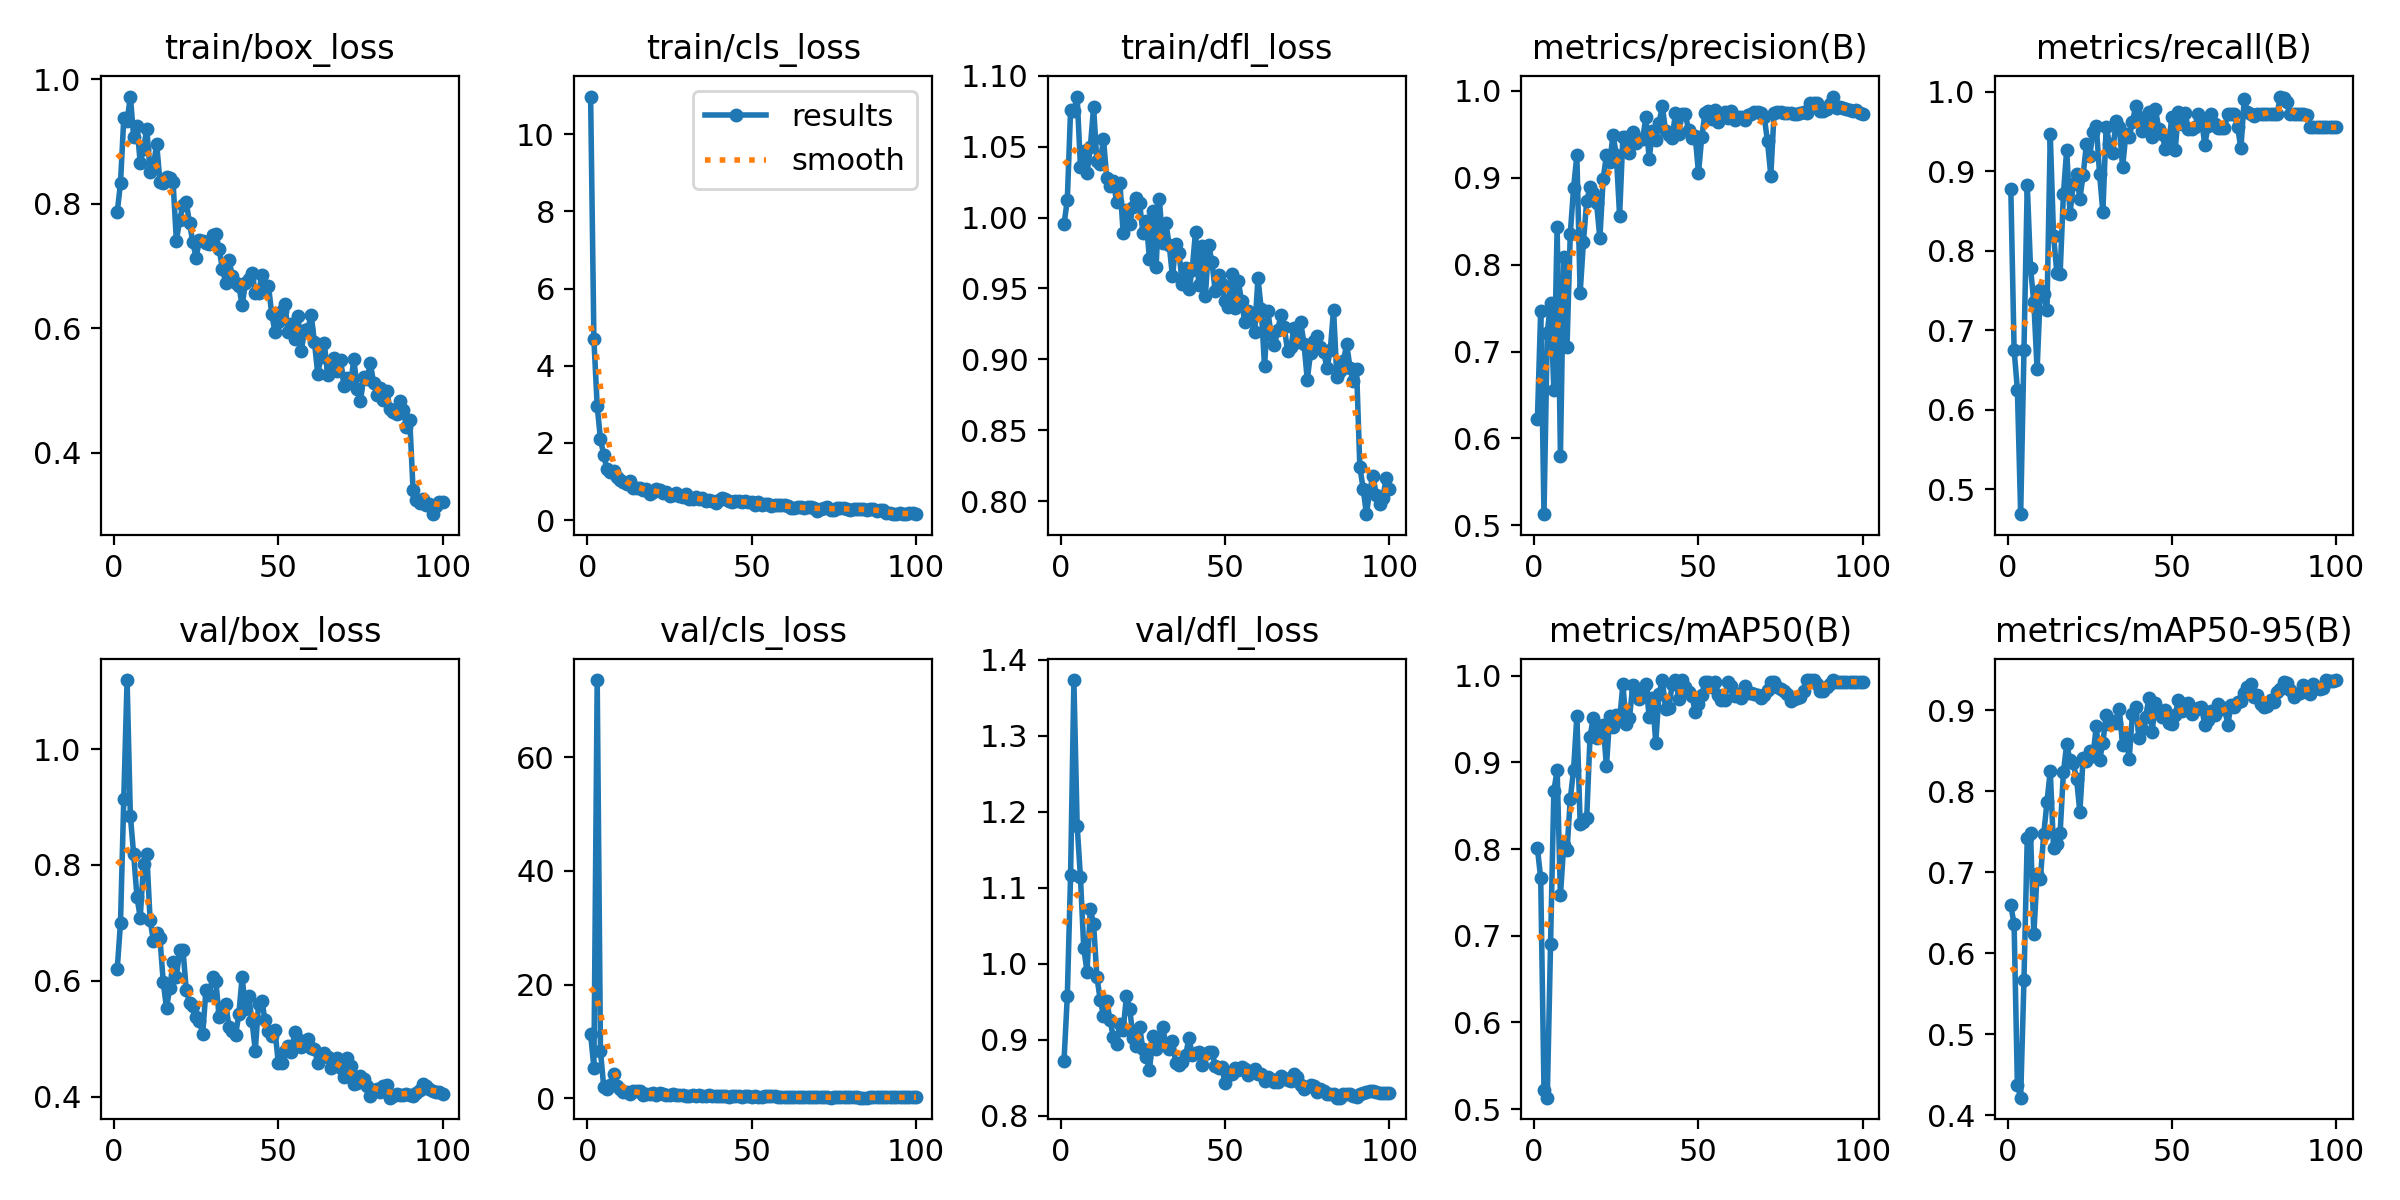

In [6]:
# curvas de loss y mAP en val
display(Image(filename=carpeta / "results.png", width=900))

## Evaluacion en test

In [7]:
best = YOLO(carpeta / "weights" / "best.pt")
metrics = best.val(data=str(DATA_DIR / "data.yaml"), split="test", name="yolov10s_baseline_test")

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("precision:", metrics.box.mp, "recall:", metrics.box.mr)
print("tiempos (ms por imagen):", metrics.speed)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10s summary (fused): 103 layers, 7,220,709 parameters, 0 gradients, 21.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 12.3±9.4 MB/s, size: 57.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/data/pills_yolo/labels/test... 89 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 89/89 614.0it/s 0.1s
val: New cache created: /content/data/pills_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.4it/s 2.5s
                   all         89         97      0.981      0.985      0.985      0.902
             Cipro 500         24         26      0.985      0.923      0.925      0.877
   Ibuphil Cold 400-60         10         10       0.97          1      0.995      0.975
       

In [8]:
# AP por clase
for i, c in enumerate(metrics.box.ap_class_index):
    print(clases[c], "AP50 =", round(metrics.box.ap50[i], 3), " AP50-95 =", round(metrics.box.ap[i], 3))

Cipro 500 AP50 = 0.925  AP50-95 = 0.877
Ibuphil Cold 400-60 AP50 = 0.995  AP50-95 = 0.975
Xyzall 5mg AP50 = 0.995  AP50-95 = 0.833
blue AP50 = 0.995  AP50-95 = 0.938
pink AP50 = 0.995  AP50-95 = 0.936
red AP50 = 0.995  AP50-95 = 0.86
white AP50 = 0.995  AP50-95 = 0.898


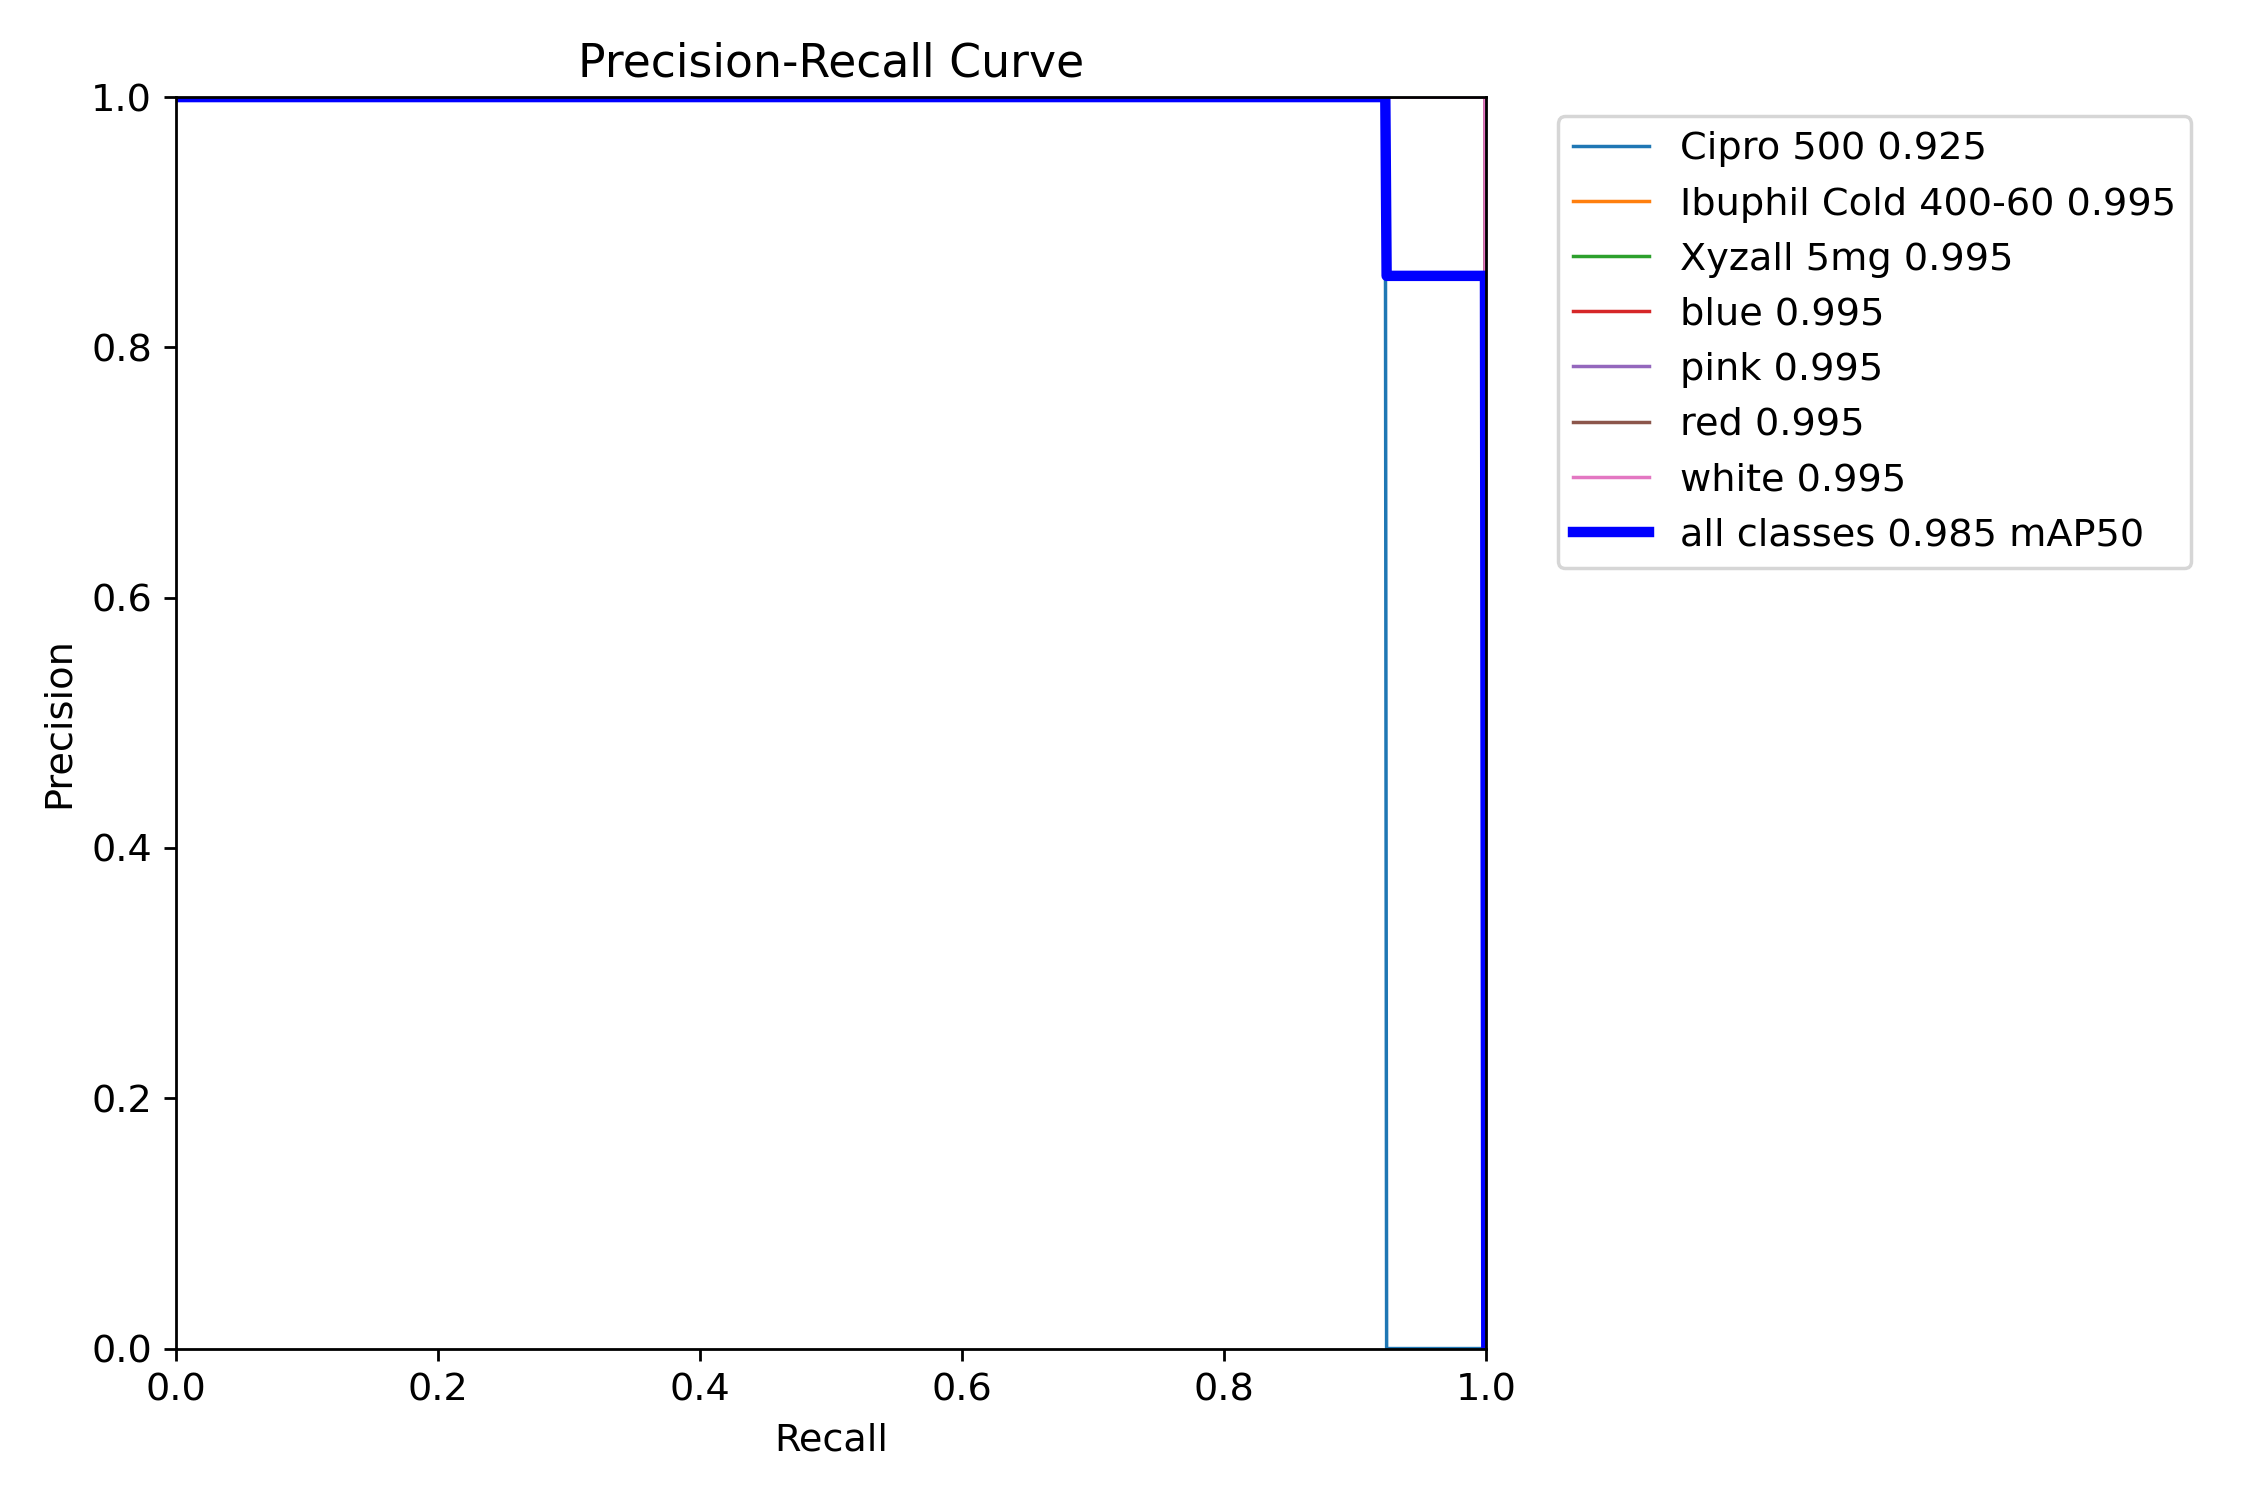

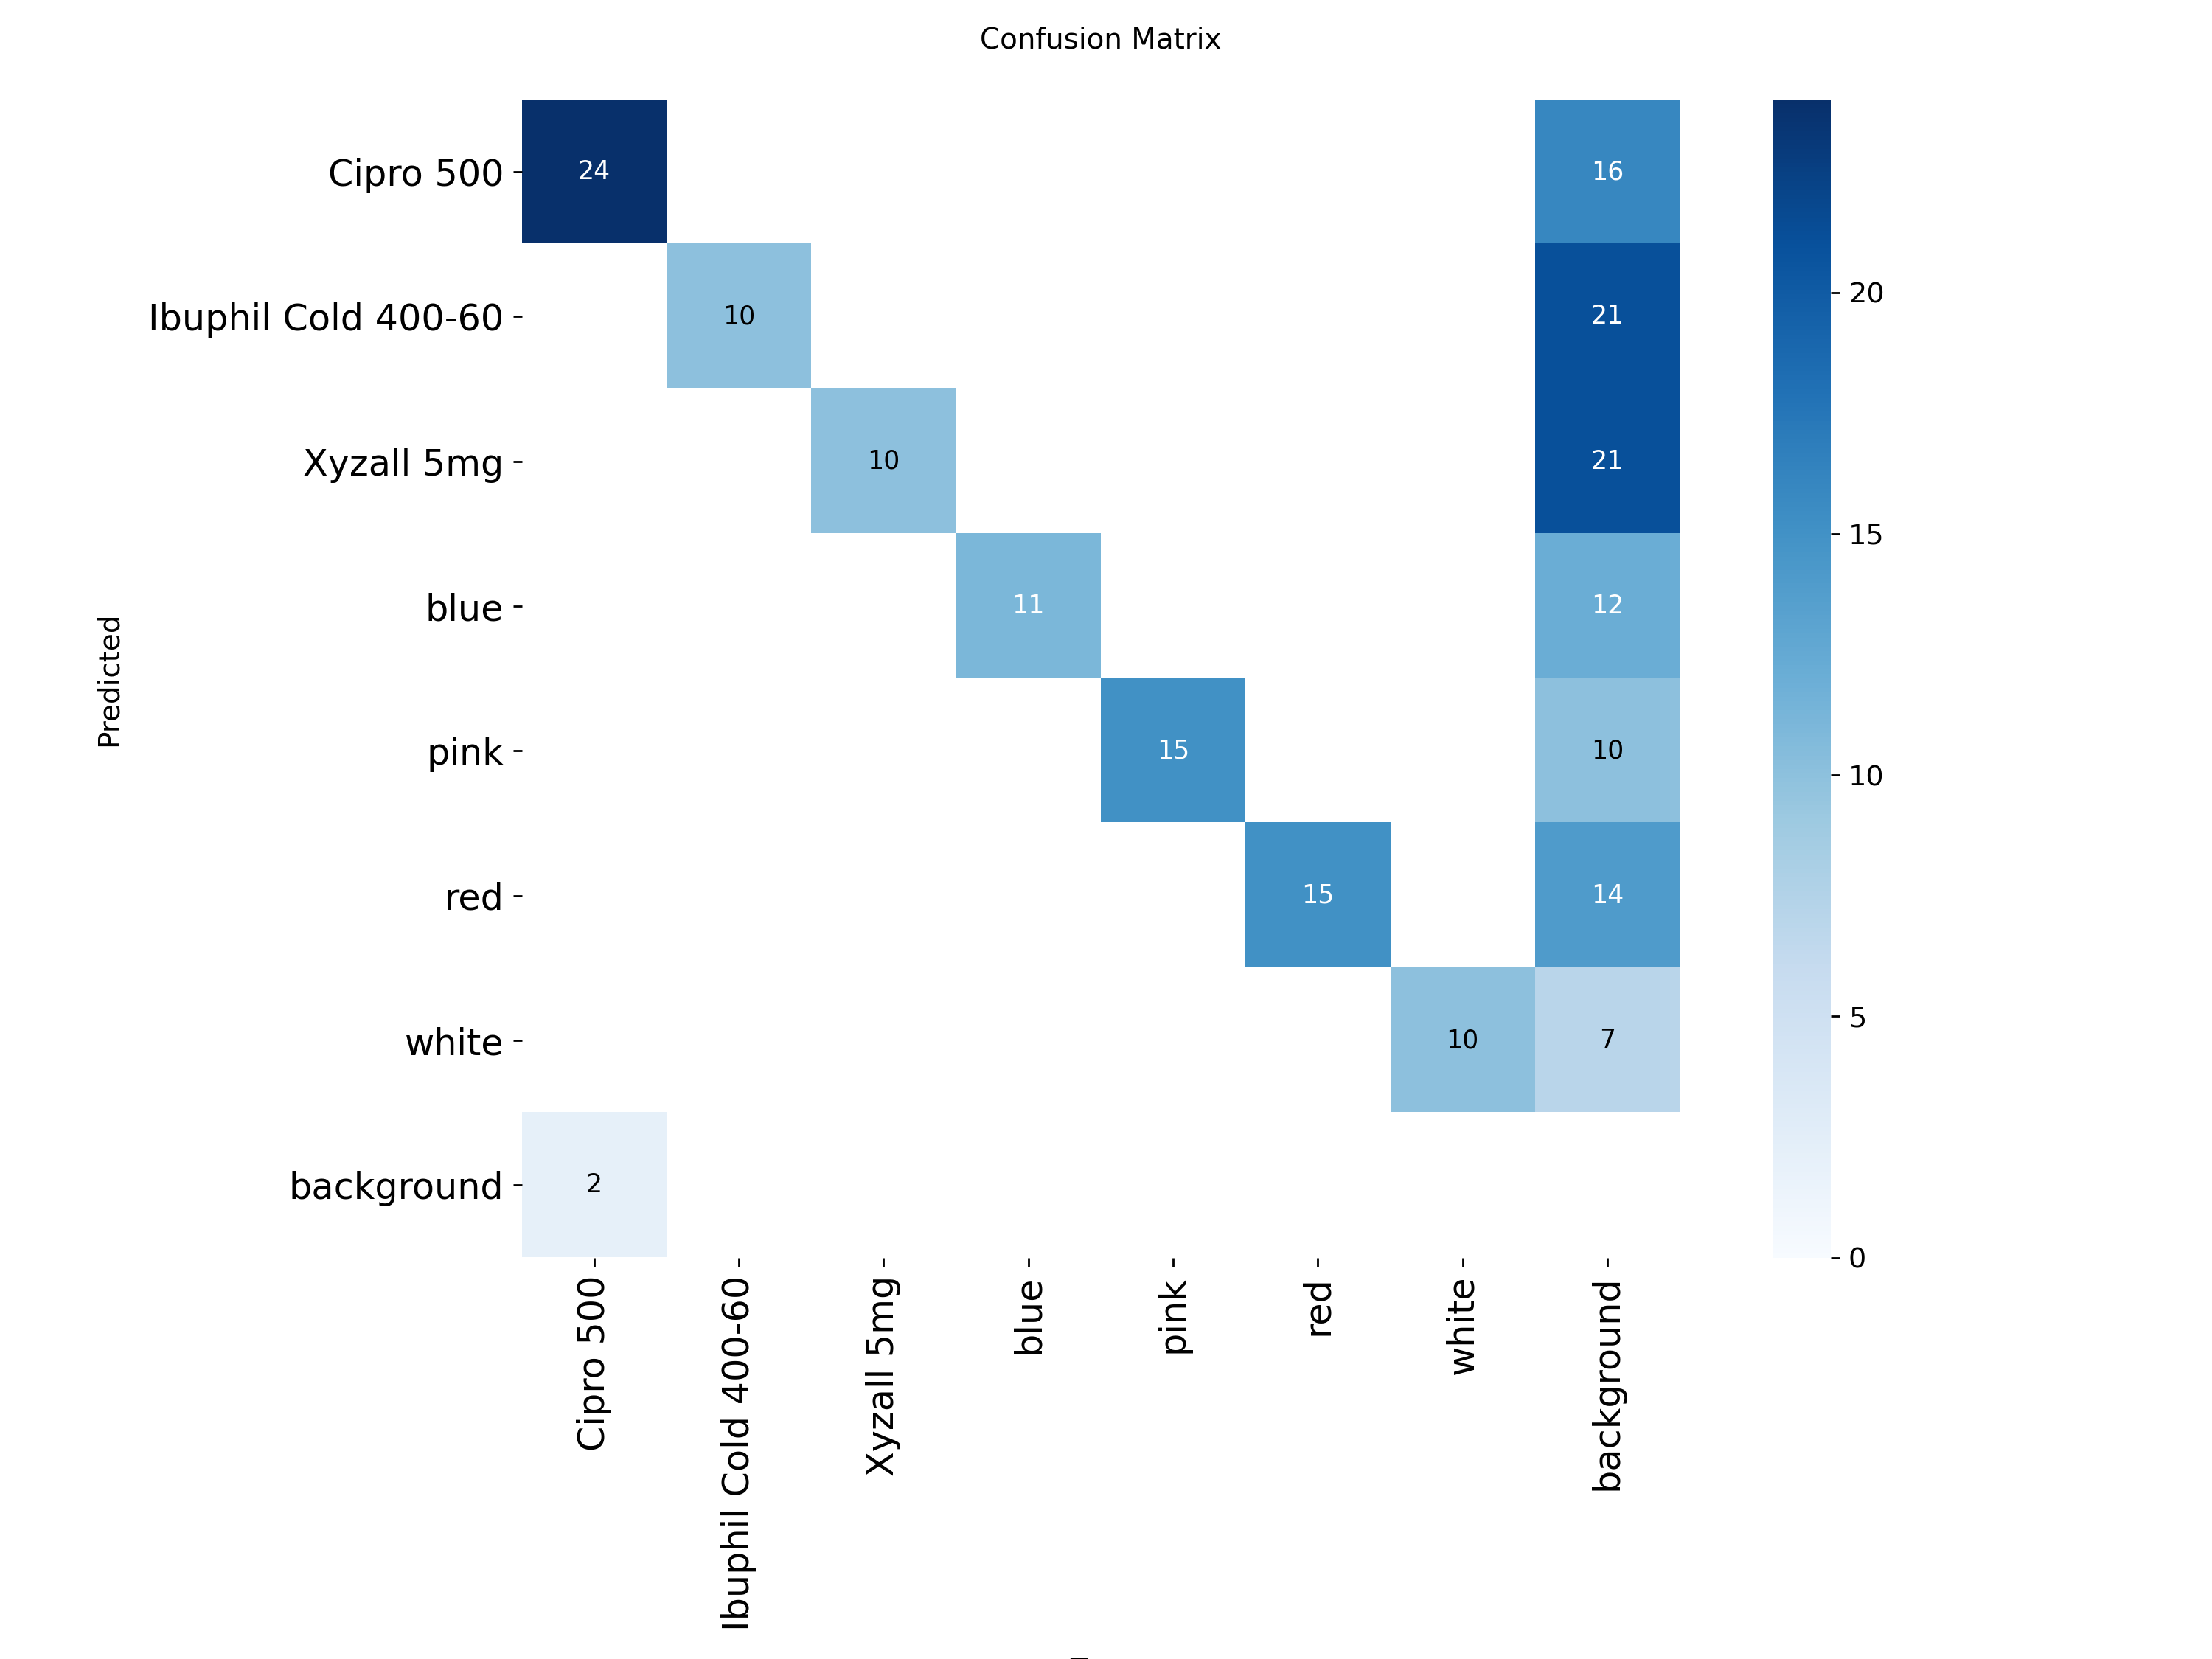

In [9]:
# curva PR y matriz de confusion (las guarda ultralytics)
display(Image(filename=Path(metrics.save_dir) / "BoxPR_curve.png", width=700))
display(Image(filename=Path(metrics.save_dir) / "confusion_matrix.png", width=700))

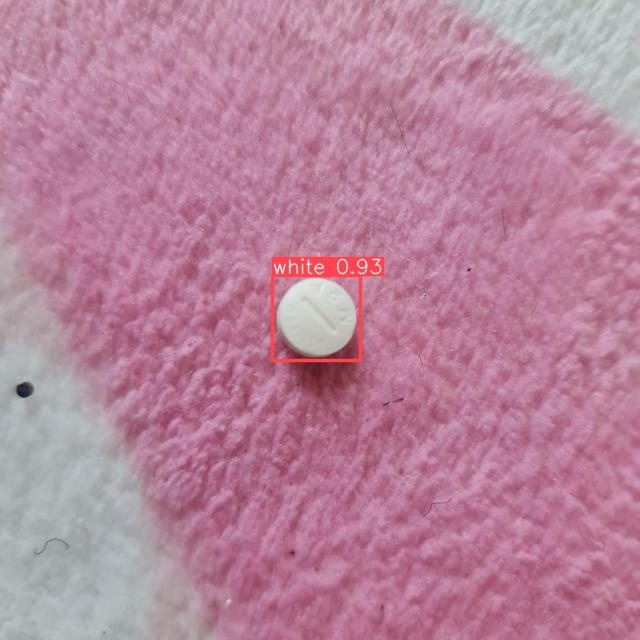

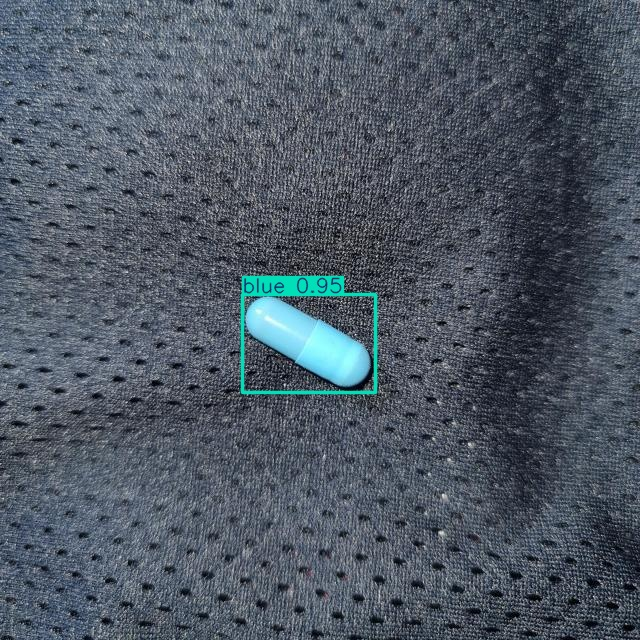

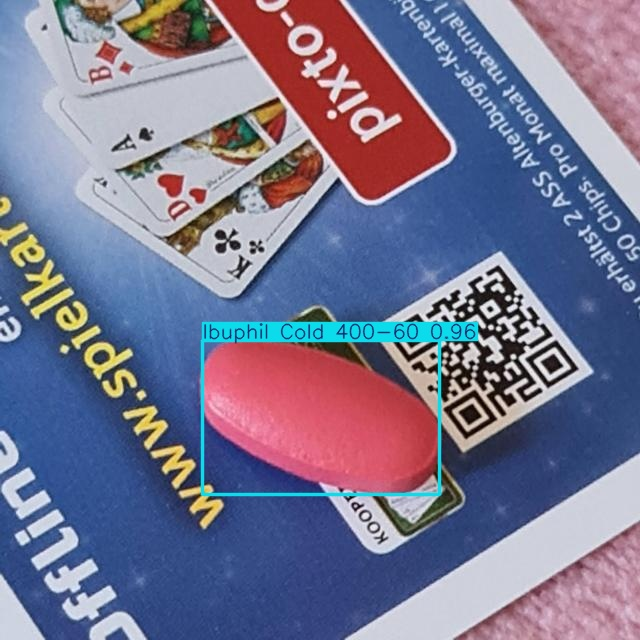

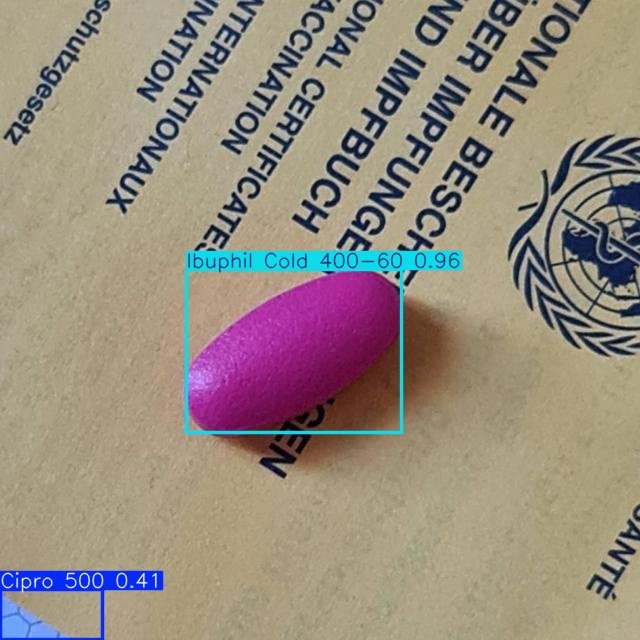

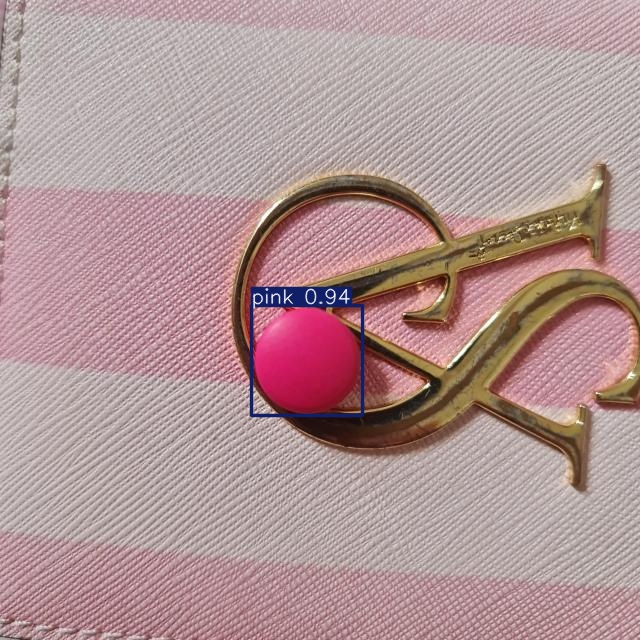

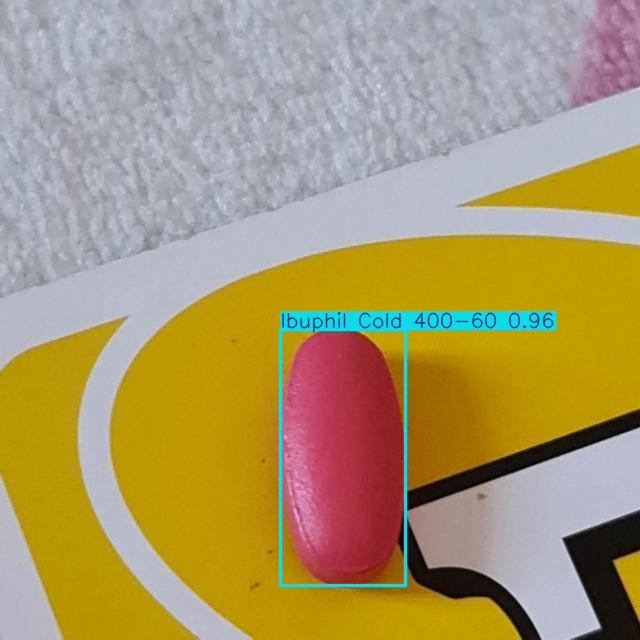

In [10]:
# algunas predicciones en test
imgs = sorted((DATA_DIR / "images" / "test").glob("*.jpg"))[:6]
for r in best.predict(imgs, verbose=False):
    display(Image(data=cv2.imencode(".jpg", r.plot())[1].tobytes(), width=400))

In [10]:
# para hacer el analisis TIDE sin reentrenar: descomentar y ejecutar en vez de la celda de entrenar
# best = YOLO("runs/runs/detect/yolov10s_baseline/weights/best.pt")
# metrics = best.val(data=str(DATA_DIR / "data.yaml"), split="test")

Ultralytics 8.4.215  Python-3.8.20 torch-2.4.1 CPU (AMD Ryzen AI 7 350 w/ Radeon 860M)
YOLOv10s summary (fused): 103 layers, 7,220,709 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 500.0±215.4 MB/s, size: 77.8 KB)
val: Scanning C:\Users\mcasa\OneDrive - Universidade de Santiago de Compostela\Escritorio\VisComp\Practicas\Practica_Final\CV1_P6\data\pills_yolo\labels\test.cache... 89 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 89/89  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.2s/it 7.0s1.5ss
                   all         89         97      0.982      0.985      0.985      0.905
             Cipro 500         24         26      0.988      0.923      0.925      0.877
   Ibuphil Cold 400-60         10         10      0.971          1      0.995      0.975
            Xyzall 5mg         10         10          1       0.97      0.995      0.833
                  blue    

## Analisis de errores (TIDE)

Como en la seccion 9 de `p1_map_visual`: miramos que tipo de error nos quita mAP (localizacion, clasificacion, duplicados, fondo o pastillas no detectadas). Para cada tipo se arreglan esos errores, se recalcula el mAP y se ve cuanto se gana.

En clase se hace con IoU 0.5, pero nuestro mAP50 ya es casi 1 y ahi no hay casi nada que mejorar. Por eso lo hacemos con el **mAP50-95**: repetimos el analisis con los 10 umbrales de IoU (0.5, 0.55 ... 0.95) y hacemos la media.

No hace falta reentrenar, solo predecimos en test con best.pt. Hay que subir `mapviz.py` a Colab.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import mapviz as mv

# mapviz quiere listas de diccionarios con las cajas en pixeles (x1, y1, x2, y2)
img_dir = DATA_DIR / "images" / "test"
lbl_dir = DATA_DIR / "labels" / "test"

gts, preds = [], []
for r in best.predict(sorted(img_dir.glob("*.jpg")), conf=0.001, stream=True, verbose=False):
    nombre = Path(r.path).stem
    H, W = r.orig_shape

    # GT: pasar de cx cy w h normalizado a esquinas en pixeles
    for linea in open(lbl_dir / (nombre + ".txt")).read().splitlines():
        c, cx, cy, w, h = linea.split()
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        gts.append(dict(img=nombre, cls=clases[int(c)], box=(cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)))

    for box, s, c in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist()):
        preds.append(dict(img=nombre, cls=clases[int(c)], box=box, score=s))

# comprobar que da casi lo mismo que ultralytics
print("mAP50-95 mapviz:", round(mv.map_coco(gts, preds), 3), " ultralytics:", round(metrics.box.map, 3))

mAP50-95 mapviz: 0.907  ultralytics: 0.905


0.5 mAP = 0.987  ganancia localizacion = 0.0
0.55 mAP = 0.987  ganancia localizacion = 0.0
0.6 mAP = 0.987  ganancia localizacion = 0.0
0.65 mAP = 0.987  ganancia localizacion = 0.0
0.7 mAP = 0.987  ganancia localizacion = 0.0
0.75 mAP = 0.987  ganancia localizacion = 0.0
0.8 mAP = 0.949  ganancia localizacion = 0.038
0.85 mAP = 0.896  ganancia localizacion = 0.091
0.9 mAP = 0.818  ganancia localizacion = 0.168
0.95 mAP = 0.485  ganancia localizacion = 0.504
localizacion 0.08
clasificacion 0.001
duplicados 0.0
fondo 0.001
no detectadas 0.006


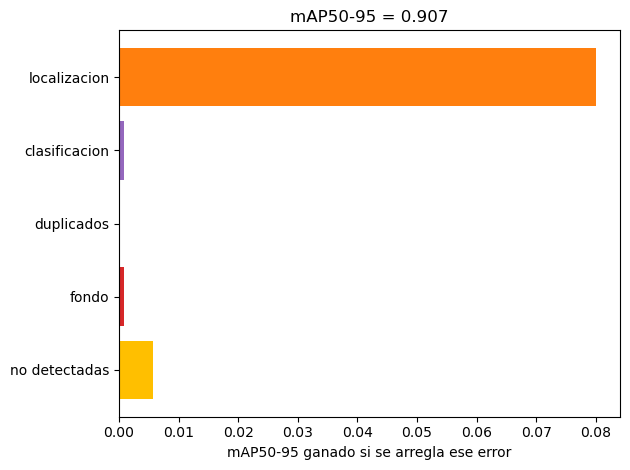

In [12]:
umbrales = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
tipos = ["loc", "cls", "dup", "bg", "miss"]
base = []
delta = {k: [] for k in tipos}
for t in umbrales:
    r = mv.error_breakdown(gts, preds, iou_thr=t)
    base.append(r["base"])
    for k in tipos:
        delta[k].append(r["delta"][k])
    print(t, "mAP =", round(r["base"], 3), " ganancia localizacion =", round(r["delta"]["loc"], 3))

# la media de los 10 umbrales es lo que se ganaria en mAP50-95
ganancia = [np.mean(delta[k]) for k in tipos]
nombres = ["localizacion", "clasificacion", "duplicados", "fondo", "no detectadas"]
for n, g in zip(nombres, ganancia):
    print(n, round(g, 3))

plt.barh(nombres, ganancia, color=[mv.ERROR_COLORS[k] for k in tipos])
plt.gca().invert_yaxis()
plt.xlabel("mAP50-95 ganado si se arregla ese error")
plt.title(f"mAP50-95 = {np.mean(base):.3f}")
plt.tight_layout()
plt.show()

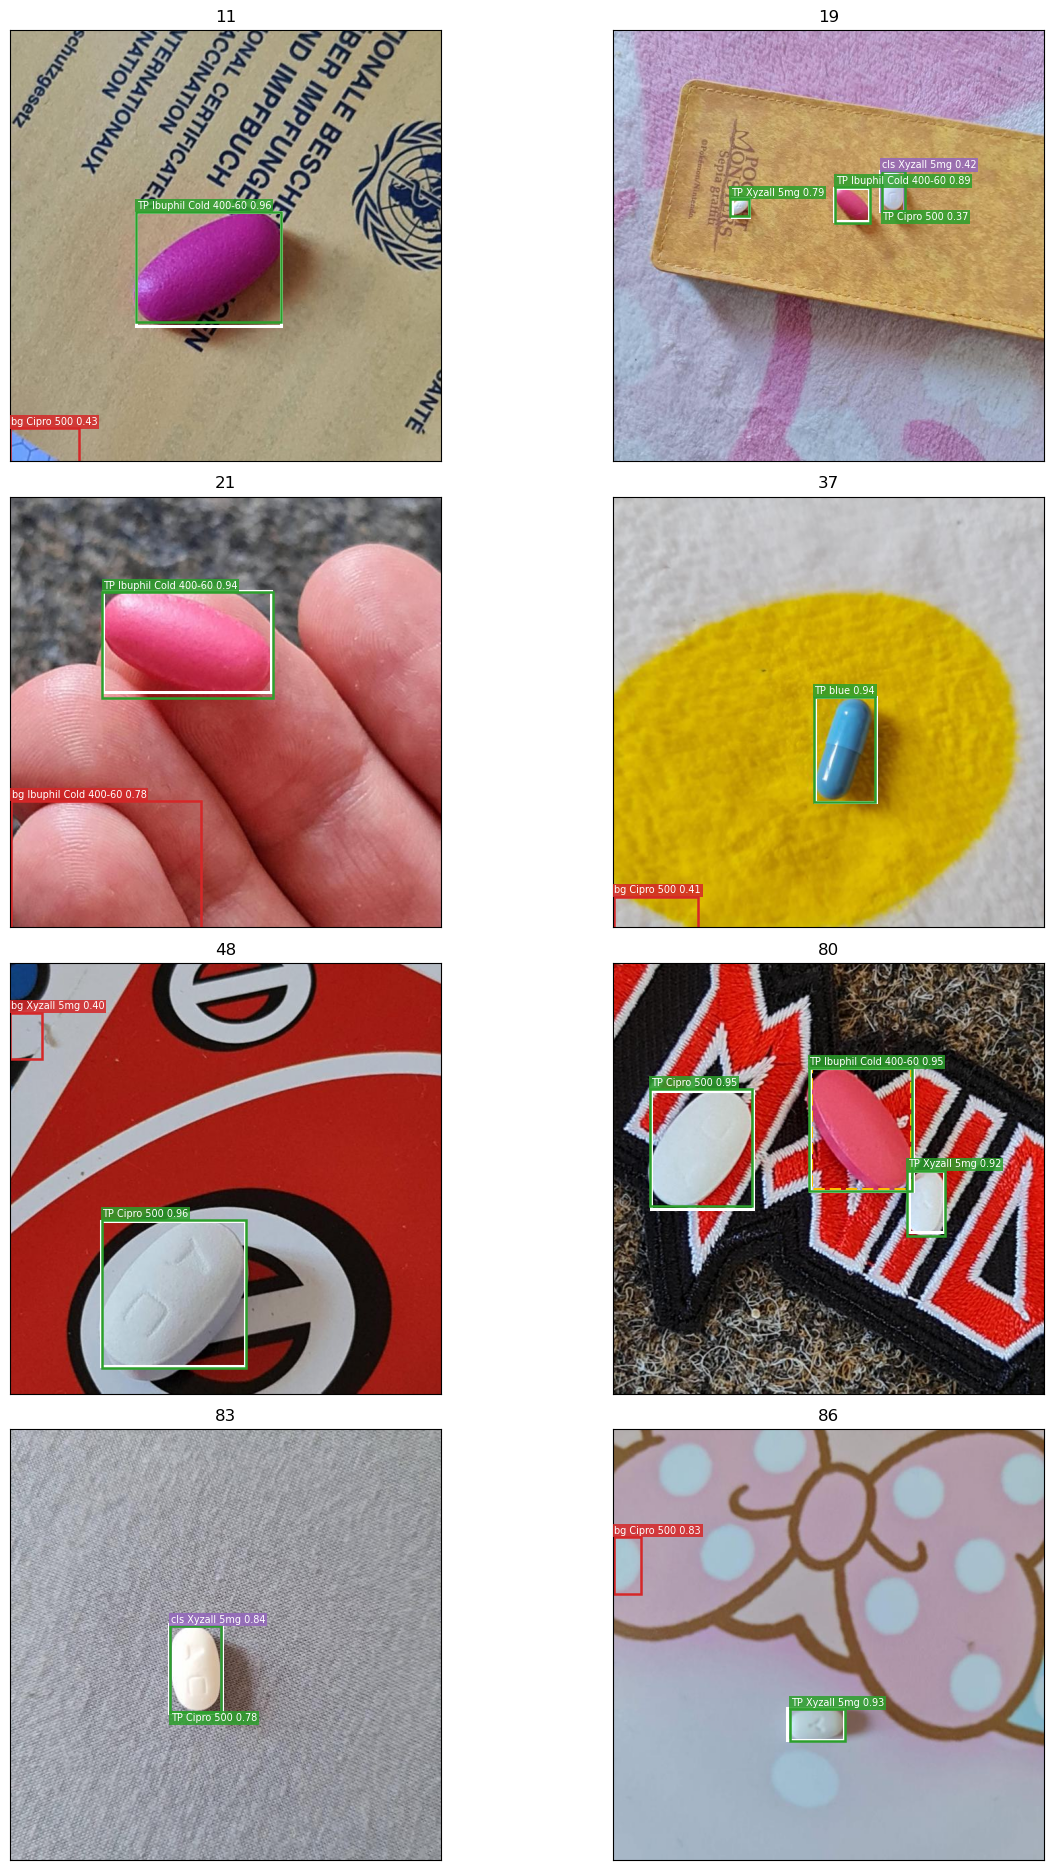

In [13]:
# imagenes con errores de score alto o pastillas no detectadas
# (para dibujar usamos IoU 0.5, con IoU alto las cajas casi coinciden con la GT y no se ve nada)
res = mv.error_breakdown(gts, preds)
imgs = sorted({p["img"] for p, t in zip(preds, res["types"]) if t != "TP" and p["score"] > 0.3}
              | {gts[j]["img"] for j in res["missed"]})
fotos = {n: cv2.imread(str(img_dir / (n + ".jpg")))[:, :, ::-1] for n in imgs}
mv.show_errors(gts, preds, res, imgs, image=fotos, min_score=0.3)

### Conclusiones

- Con el mAP50-95 casi todo lo que falta es **localizacion**: arreglarla subiria el mAP50-95 unos 0.08. Lo demas casi no cuenta (no detectadas +0.006, clasificacion +0.001).
- Hasta IoU 0.75 no se pierde nada, la perdida esta entre 0.8 y 0.95: el modelo encuentra las pastillas y acierta la clase, pero las cajas no estan del todo ajustadas.
- Los 2 "missed GT" de la imagen 80 son fallos de la anotacion: la pastilla rosa esta anotada dos veces (como `Cipro 500` y como `Ibuphil Cold 400-60`) y hay una caja `Cipro 500` de menos de 1 pixel.
- Clasificacion y fondo son pocos casos: 2 `Cipro 500` que tambien predice como `Xyzall 5mg`, y las cajas de fondo salen casi todas pegadas al borde de la imagen.

Para mejorar habria que probar cosas que ajusten mejor las cajas: mas epocas, mas resolucion (`imgsz`) o mas peso a la loss de la caja (`box`).